<a href="https://colab.research.google.com/github/souvik-brz/is901e-assignments/blob/main/E26133078_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [82]:
# Import libraries

!pip install datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

In [83]:
# Part 1 : Dataset preprocessing

dataset= load_dataset("gvlassis/california_housing")

training_df = dataset['train'].to_pandas()
validation_df = dataset['validation'].to_pandas()
testing_df = dataset['test'].to_pandas()

In [84]:
# Part 2: Building the Feature Matrix

feature_columns = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude"
    ]

X_training_df = np.column_stack(
    (np.ones(len(training_df)), training_df[feature_columns].to_numpy())
    )

X_validation_df = np.column_stack(
    (np.ones(len(validation_df)), validation_df[feature_columns].to_numpy())
    )

X_testing_df = np.column_stack(
    (np.ones(len(testing_df)), testing_df[feature_columns].to_numpy())
    )

In [85]:
# Part 3 : Building the Output Matrix

value_column = ["MedHouseVal"]

y_training_df = training_df[value_column].to_numpy()
y_validation_df = validation_df[value_column].to_numpy()
y_testing_df = testing_df[value_column].to_numpy()

In [86]:
# Part 4: Performing Linear Regression

lambda_reg = 1.0
I = np.eye(X_training_df.shape[1])

w = np.linalg.inv(X_training_df.T @ X_training_df + lambda_reg * I) @ X_training_df.T @ y_training_df
print("Optimal weight vector: \n", w)

Optimal weight vector: 
 [[-1.56232897e+01]
 [ 4.82058600e-01]
 [ 1.36252132e-02]
 [-1.58159861e-01]
 [ 8.19714418e-01]
 [ 6.18537852e-06]
 [-1.05340306e-02]
 [-2.22019054e-01]
 [-1.94862140e-01]]


In [87]:
# Part 5: Calculating Test Loss

y_prediction_df = X_testing_df @ w

test_loss = np.sum((y_testing_df- y_prediction_df) ** 2)
print("Test Loss:", test_loss)

Test Loss: 731.2029561670112


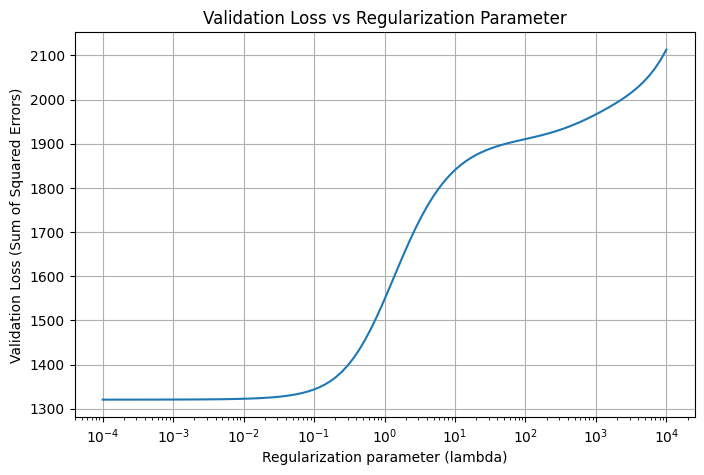

Best lambda: 0.0001
Minimum validation loss: 1320.4669744284608
Corresponding test loss: 683.1233277535097


In [88]:
# Part 6: Hyperparameter Tuning

validation_losses = []
test_losses = []
weights_list = []

lambda_values = np.logspace(-4, 4, 100)

for lambda_reg in lambda_values:

    w_temp = np.linalg.solve(X_training_df.T @ X_training_df + lambda_reg * np.eye(X_training_df.shape[1]), X_training_df.T @ y_training_df)

    y_val_prediction = X_validation_df @ w_temp
    val_loss = np.sum((y_validation_df - y_val_prediction) ** 2)
    validation_losses.append(val_loss)

    y_test_prediction = X_testing_df @ w_temp
    test_loss = np.sum((y_testing_df - y_test_prediction) ** 2)
    test_losses.append(test_loss)

    weights_list.append(w_temp)

best_index = np.argmin(validation_losses)
best_lambda = lambda_values[best_index]
best_val_loss = validation_losses[best_index]
best_test_loss = test_losses[best_index]
best_w = weights_list[best_index]

plt.figure(figsize=(8, 5))
plt.plot(lambda_values, validation_losses)
plt.xscale("log")
plt.xlabel("Regularization parameter (lambda)")
plt.ylabel("Validation Loss (Sum of Squared Errors)")
plt.title("Validation Loss vs Regularization Parameter")
plt.grid(True)
plt.show()

print("Best lambda:", best_lambda)
print("Minimum validation loss:", best_val_loss)
print("Corresponding test loss:", best_test_loss)